# 필요 SNR (T) 1차 — 소리를 2 dB씩 줄이며 판정·방향이 언제 무너지나 (Step8d)

> 2026-10-28 녹음 · 녹음 도구 [`board/stream_capture.py`](../board/stream_capture.py) · B0 점수 [`harmonic/score.py`](../harmonic/score.py) · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다. 사용자가 확인한 뒤 Step8d 결과로 올린다.

**질문:** 탐지거리 식 r = 10^((L₁ − N − T) ÷ 20)의 **T**(필요 SNR)는 얼마인가? 지금은 근거 없이 10 dB로 가정했다. T가 10 dB에서 6 dB 바뀌면 거리가 2배 바뀐다.

| 조건 | 값 |
|---|---|
| 재생 파일 | 1차 `51_T_fpv_steps.wav`: 0 ~ −40 dB, 2 dB씩 21단계 × 30 s. 재측정 `53_T_fpv_steps60.wav`: 0 ~ −60 dB, 31단계 × 20 s. 둘 다 같은 FPV 6 s 발췌 반복, 앞뒤 20 s 무음 |
| 배치 | 노트북 스피커, 배열 0° · 0.5 m, 보정(spl_cal) 때와 같은 음량·트리머 |
| 녹음 | 1차 `T_fpv/` — B1을 누르지 않아 보드는 켤 때 배운 배경을 씀 (방향 무효, 7절). 재측정 `T2_fpv/` — 녹음 직전 USB를 다시 꽂아 배경을 새로 배움 |
| 1차 Mini 3 | `T_mini3/` 녹음은 재측정 녹음에 덮어써져 없어졌다. 2026-10-28 첫 실행 결과(재현 불가): B0 T50 −3.4 dB, T90 +1.0 dB, 방향은 무효. Mini 3 재측정(`54_T_mini3_steps60.wav`, `T2_mini3/`)이 오면 이 노트북에 더한다 |

**측정 전에 고정한 정의 (Step8d, 2026-10-28)**
- **SNR** = ch1의 300 ~ 3000 Hz 대역에서 (창 전력 − 바닥 전력) ÷ 바닥 전력 [dB]. 바닥 = 재생 전 조용한 구간. 창마다 재고 2 dB 칸으로 묶는다
- **B0 판정 성공** = 1 s 창의 B0 점수(40 ~ 700 Hz) ≥ 13.1. 조용한 창 규칙은 끈다
- **방향 성공** = 보드 결과(`doa_mcu.csv`)가 유효·소리 있음이고, 높은 SNR 구간의 방위 중앙값과 ±10° 안

**한계:** 바닥은 조용한 방이다 (거리 계산에서는 실제 N을 넣는다). 잡음 종류가 다르면 T가 달라질 수 있다. 원음은 고정익이 아니라 멀티로터다.

In [1]:
import json, csv, sys
import numpy as np, soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
sys.path.insert(0, "..")
import harmonic.score as hs
FS = 12500; THR_B0 = 13.1
CANDS = [hs.candidates(40, 700)]
LAB = {"T_fpv": "FPV 1차", "T2_fpv": "FPV 재측정"}
STEP = {"T_fpv": 30, "T2_fpv": 20}; NSTEP = {"T_fpv": 21, "T2_fpv": 31}   # 단계 길이 [s], 단계 수
def band_p(seg, lo=300, hi=3000):
    w = np.hanning(len(seg)); X = np.fft.rfft((seg - seg.mean()) * w); f = np.fft.rfftfreq(len(seg), 1 / FS)
    m = (f >= lo) & (f < hi)
    return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(w ** 2))
db = lambda p: 10 * np.log10(2 * p + 1e-30)
REC = {}
for lab in LAB:
    x, fs = sf.read(f"../dumps/stream/{lab}/seg_000.wav", dtype="float64"); assert fs == FS
    S = json.load(open(f"../dumps/stream/{lab}/summary.json", encoding="utf-8"))
    REC[lab] = dict(x=x[:, 0] - x[:, 0].mean(), start=S["segments"][0]["start_sample"], S=S)
    print(f"{LAB[lab]}: {len(x) / FS:.1f} s, 판정 {S['criteria']}, 클리핑 패킷 {S['packets']['clip_packets']}, 보드 방향 결과 {S['doa']['results']}개 (유효 {S['doa']['valid']})")

FPV 1차: 678.1 s, 판정 {'loss': True, 'ovr': True, 'crc': True, 'clip': True, 'time_restore': True}, 클리핑 패킷 0, 보드 방향 결과 2759개 (유효 976)
FPV 재측정: 694.9 s, 판정 {'loss': True, 'ovr': True, 'crc': True, 'clip': True, 'time_restore': True}, 클리핑 패킷 0, 보드 방향 결과 2828개 (유효 771)


## 1. 시간축 — 계단이 보이나

0.5 s마다 1 s 창의 300 ~ 3000 Hz 크기(ch1). 재생 시작은 바닥보다 10 dB 이상인 상태가 **3 s 이상 이어지는** 첫 시각으로 찾는다 (재생 버튼·마우스 같은 짧은 소리를 시작으로 잡지 않으려고).
**예상:** 시작 뒤 30 s마다 2 dB씩 내려가는 계단 21개, 끝에서 바닥으로 돌아감. 보정 음량이면 0단계가 바닥보다 약 40 dB 위 (추정).

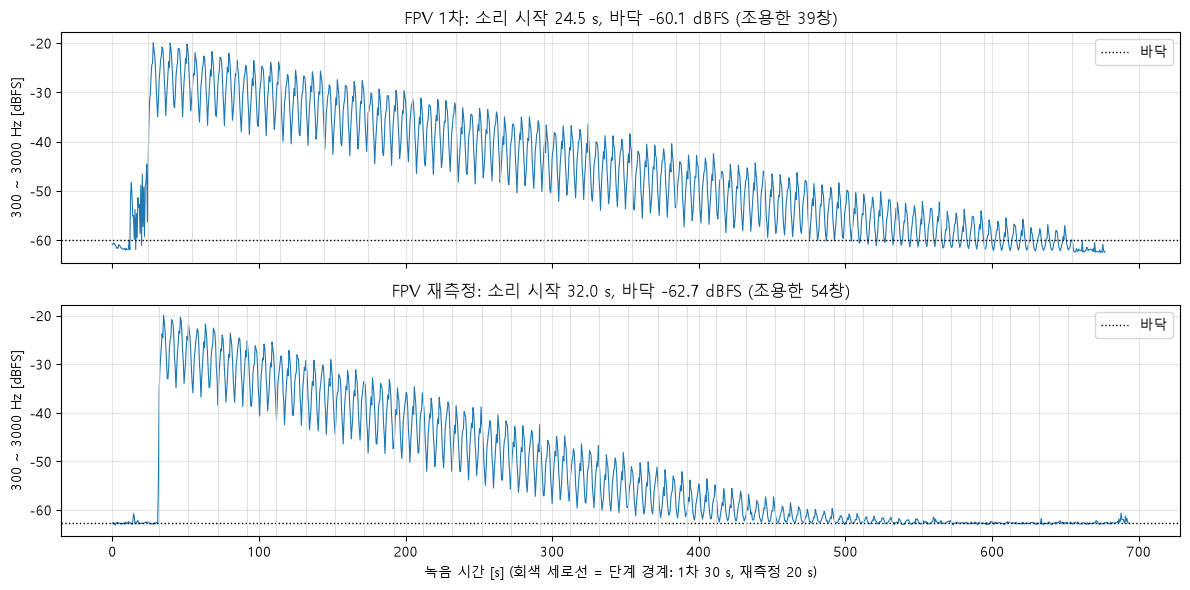

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for a, lab in zip(ax, LAB):
    R = REC[lab]; x = R["x"]
    t = np.arange(0, len(x) / FS - 1, 0.5)
    L = np.array([db(band_p(x[int(s * FS):int(s * FS) + FS])) for s in t])
    q = (t > 3) & (t < 12)                                  # B1을 누른 뒤, 재생 전
    fl0 = np.median(L[q])
    hi = (t > 12) & (L > fl0 + 10)
    run = np.convolve(hi, np.ones(6, int), "full")[5:]       # 이 창부터 6창(3 s) 연속인가
    on = t[np.argmax(run[:len(t)] == 6)]                     # 재생(소리) 시작
    quiet = (t > 3) & (t < on - 1.5)
    R.update(t=t, L=L, onset=on, floor_p=np.median([band_p(x[int(s * FS):int(s * FS) + FS]) for s in t[quiet]]))
    a.plot(t, L, lw=.8); a.axhline(db(R["floor_p"]), color="k", ls=":", lw=1, label="바닥")
    for i in range(NSTEP[lab] + 1): a.axvline(on + STEP[lab] * i, color="0.85", lw=.6)
    a.set_title(f"{LAB[lab]}: 소리 시작 {on:.1f} s, 바닥 {db(R['floor_p']):.1f} dBFS (조용한 {quiet.sum()}창)"); a.set_ylabel("300 ~ 3000 Hz [dBFS]"); a.grid(alpha=.3); a.legend(loc="upper right")
ax[-1].set_xlabel("녹음 시간 [s] (회색 세로선 = 단계 경계: 1차 30 s, 재측정 20 s)"); plt.tight_layout(); plt.show()

## 2. 창마다 SNR과 B0 점수

1 s 창, 0.5 s 이동 (Step8b와 같은 창). 창 SNR = 10·log₁₀((P − N) ÷ N), P ≤ N이면 신호 없음.
B0 점수는 `harmonic/score.py` 그대로 (기본음 40 ~ 700 Hz, 고조파 4개, 주변 ±100 Hz 중앙값과 비교).

In [3]:
for lab in LAB:
    R = REC[lab]; x = R["x"]; N = R["floor_p"]
    t = np.arange(3, len(x) / FS - 1, 0.5)
    P = np.array([band_p(x[int(s * FS):int(s * FS) + FS]) for s in t])
    snr = np.where(P > N, 10 * np.log10(np.maximum(P - N, 1e-30) / N), -np.inf)
    sc = np.array([hs.score(x[int(s * FS):int(s * FS) + FS], CANDS)[0] for s in t])
    step = np.floor((t - R["onset"]) / STEP[lab]).astype(int)
    R.update(wt=t, snr=snr, score=sc[:, 0], f0=sc[:, 1], step=step)
    pre = t < R["onset"] - 1.5; fa = pre & (sc[:, 0] >= THR_B0)
    print(f"{LAB[lab]}: 창 {len(t)}개, 소리 시작 {R['onset']:.1f} s, 재생 전 창의 B0 성공(오탐) {fa.sum()}/{pre.sum()} = {fa.sum() / pre.sum():.0%}, 그 기본음 {np.round(sc[fa, 1]).astype(int).tolist()} Hz")

FPV 1차: 창 1349개, 소리 시작 24.5 s, 재생 전 창의 B0 성공(오탐) 6/40 = 15%, 그 기본음 [50, 50, 50, 50, 48, 48] Hz


FPV 재측정: 창 1382개, 소리 시작 32.0 s, 재생 전 창의 B0 성공(오탐) 3/55 = 5%, 그 기본음 [63, 63, 68] Hz


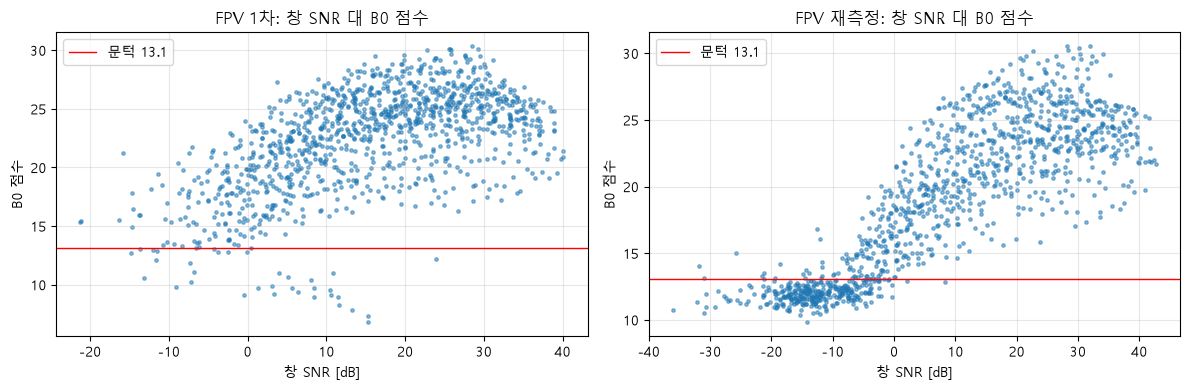

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, lab in zip(ax, LAB):
    R = REC[lab]; m = np.isfinite(R["snr"])
    a.scatter(R["snr"][m], R["score"][m], s=6, alpha=.5)
    a.axhline(THR_B0, color="r", lw=1, label=f"문턱 {THR_B0}")
    a.set_xlabel("창 SNR [dB]"); a.set_ylabel("B0 점수"); a.set_title(f"{LAB[lab]}: 창 SNR 대 B0 점수"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## 3. 한 창 손으로 따라가기

FPV 재측정에서 B0 점수가 문턱 근처(13.1 ± 2)인 창 하나를 골라, SNR과 점수가 어떻게 나오는지 숫자로 본다.
**예상:** SNR = 10·log₁₀((P − N) ÷ N). 예를 들어 P가 N의 11배면 (11 − 1) ÷ 1 = 10 → 10 dB.

In [5]:
R = REC["T2_fpv"]; i = int(np.argmin(np.abs(R["score"] - THR_B0) + 100 * ~np.isfinite(R["snr"])))
s0 = R["wt"][i]; w = R["x"][int(s0 * FS):int(s0 * FS) + FS]
P = band_p(w); N = R["floor_p"]
print(f"창 {s0:.1f} ~ {s0 + 1:.1f} s (단계 {R['step'][i]}: 재생 기준 {-2 * R['step'][i]} dB)")
print(f"P = {P:.3e} ({db(P):.1f} dBFS), N = {N:.3e} ({db(N):.1f} dBFS)")
print(f"P ÷ N = {P / N:.2f} → SNR = 10·log₁₀(({P / N:.2f} − 1) ÷ 1) = {10 * np.log10(P / N - 1):.1f} dB")
pk = np.clip(hs.snr_frames(w - w.mean()) - 1.0, 0.0, hs.CAP - 1.0)
c, k, ok = CANDS[0]; j = int(np.argmin(np.abs(c - R["f0"][i])))
print(f"B0: 가장 높은 기본음 {R['f0'][i]:.0f} Hz, 고조파 칸 {k[:, j].tolist()} (칸 간격 {hs.DF:.2f} Hz)")
per = [pk[:, k[h, j]].mean() for h in range(hs.H)]
print(f"   고조파별 (SNR − 1, 상한 9) 조각 평균: {np.round(per, 2).tolist()} → 합 {sum(per):.2f} = 점수 {R['score'][i]:.2f}  (문턱 {THR_B0})")

창 623.0 ~ 624.0 s (단계 29: 재생 기준 -58 dB)
P = 2.695e-07 (-62.7 dBFS), N = 2.664e-07 (-62.7 dBFS)
P ÷ N = 1.01 → SNR = 10·log₁₀((1.01 − 1) ÷ 1) = -19.4 dB
B0: 가장 높은 기본음 64 Hz, 고조파 칸 [10, 21, 31, 42] (칸 간격 6.10 Hz)
   고조파별 (SNR − 1, 상한 9) 조각 평균: [9.0, 0.82, 1.83, 1.47] → 합 13.11 = 점수 13.11  (문턱 13.1)


## 4. 보드 방향 결과를 같은 SNR로

보드(`doa_mcu.csv`)가 0.25 s마다 낸 방위를, 그 0.5 s 관측 창의 ch1 SNR로 묶는다 (위와 같은 바닥).
정답 방위 = SNR 25 dB 이상 창의 유효 방위 중앙값 (스피커가 0°지만 공통 회전 +11.4°가 보정되지 않아 숫자 대신 이걸 쓴다).

In [6]:
for lab in LAB:
    R = REC[lab]; x = R["x"]; N = R["floor_p"]
    rows = list(csv.DictReader(open(f"../dumps/stream/{lab}/doa_mcu.csv")))
    t0 = np.array([(int(r["s0"]) - R["start"]) / FS for r in rows]); fl = np.array([int(r["flags"]) for r in rows])
    ang = np.array([float(r["angle"]) for r in rows])
    ok = (t0 >= 0) & (t0 + 0.5 < len(x) / FS); t0, fl, ang = t0[ok], fl[ok], ang[ok]
    P = np.array([band_p(x[int(s * FS):int(s * FS) + 6250]) for s in t0])
    snr = np.where(P > N, 10 * np.log10(np.maximum(P - N, 1e-30) / N), -np.inf)
    good = (fl & 3) == 3
    hi = good & (snr >= 25)
    ref = np.degrees(np.angle(np.mean(np.exp(1j * np.radians(ang[hi])))))
    err = np.abs((ang - ref + 180) % 360 - 180)
    R.update(dt=t0, dsnr=snr, dok=good & (err <= 10), dref=ref, dvalid=good)
    print(f"{LAB[lab]}: 결과 {len(t0)}개, SNR ≥ 25 dB 유효 {hi.sum()}개의 방위 중앙 {ref:.1f}°, 그 안 오차 중앙 {np.median(err[hi]):.1f}°")

FPV 1차: 결과 2757개, SNR ≥ 25 dB 유효 615개의 방위 중앙 -11.2°, 그 안 오차 중앙 1.4°


FPV 재측정: 결과 2826개, SNR ≥ 25 dB 유효 514개의 방위 중앙 -12.6°, 그 안 오차 중앙 1.2°


## 5. 성공률 곡선 — T는 몇 dB인가

▶ **예측 지점 (T1)** — 아래 곡선을 보기 전에 대화에서 예측한다.

2 dB 칸마다 성공률. 칸 안 창이 10개 미만이면 그리지 않는다. 50 %·90 %를 처음 넘는 SNR(높은 쪽에서 내려오며)을 선형 보간으로 찾는다.

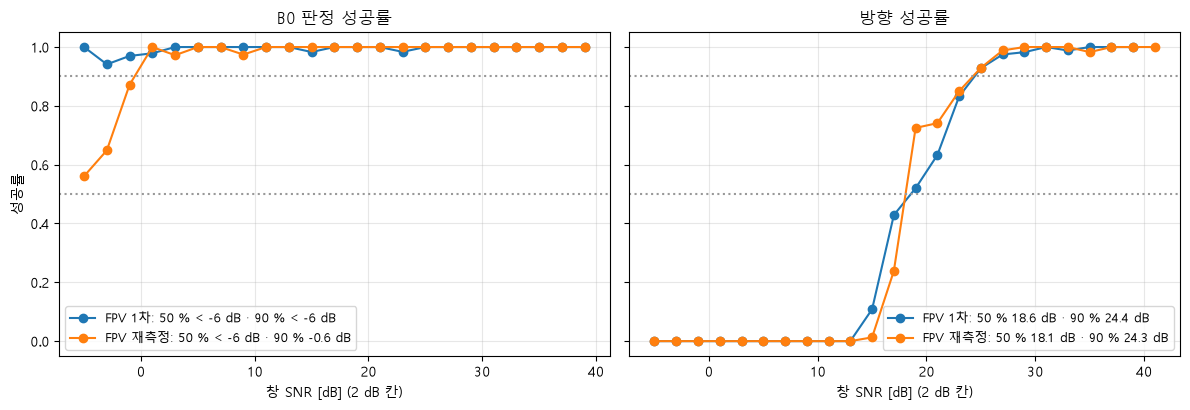

B0 판정 FPV 1차    : T50   < -6 dB, T90   < -6 dB  (가장 낮은 칸 -5 dB의 성공률 100%, 칸별 창 수 12 ~ 64)
B0 판정 FPV 재측정   : T50   < -6 dB, T90   -0.6 dB  (가장 낮은 칸 -5 dB의 성공률 56%, 칸별 창 수 19 ~ 44)
방향    FPV 1차    : T50   18.6 dB, T90   24.4 dB  (가장 낮은 칸 -5 dB의 성공률 0%, 칸별 창 수 23 ~ 128)
방향    FPV 재측정   : T50   18.1 dB, T90   24.3 dB  (가장 낮은 칸 -5 dB의 성공률 0%, 칸별 창 수 21 ~ 88)


In [7]:
BINS = np.arange(-6, 46, 2)
def curve(snr, ok):
    c, r, n = [], [], []
    for lo in BINS[:-1]:
        m = (snr >= lo) & (snr < lo + 2)
        if m.sum() >= 10: c.append(lo + 1); r.append(ok[m].mean()); n.append(m.sum())
    return np.array(c), np.array(r), np.array(n)
def cross(c, r, p):
    for i in range(len(c) - 1, 0, -1):                     # 높은 SNR에서 내려오며 처음 p 밑으로
        if r[i] >= p > r[i - 1]: return c[i - 1] + (p - r[i - 1]) / (r[i] - r[i - 1]) * (c[i] - c[i - 1])
    return np.nan
def tstr(c, r, p):                                         # 범위 밖이면 부등호로
    v = cross(c, r, p)
    if np.isfinite(v): return f"{v:.1f}"
    return f"< {c[0] - 1:.0f}" if np.all(r >= p) else (f"> {c[-1] + 1:.0f}" if np.all(r < p) else "?")
RES = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for a, (kind, key_s, key_ok) in zip(ax, (("B0 판정", "snr", None), ("방향", "dsnr", "dok"))):
    for lab in LAB:
        R = REC[lab]; snr = R[key_s]; ok = (R["score"] >= THR_B0) if key_ok is None else R[key_ok]
        play = (R["wt"] if key_ok is None else R["dt"]) > R["onset"] - 1
        c, r, n = curve(snr[play], ok[play])
        t50, t90 = cross(c, r, .5), cross(c, r, .9)
        RES[(kind, lab)] = (t50, t90, c, r, n)
        a.plot(c, r, "o-", label=f"{LAB[lab]}: 50 % {tstr(c, r, .5)} dB · 90 % {tstr(c, r, .9)} dB")
    a.axhline(.5, color="0.6", ls=":"); a.axhline(.9, color="0.6", ls=":")
    a.set_xlabel("창 SNR [dB] (2 dB 칸)"); a.set_title(f"{kind} 성공률"); a.grid(alpha=.3); a.legend(fontsize=9)
ax[0].set_ylabel("성공률"); plt.tight_layout(); plt.show()
for (kind, lab), (t50, t90, c, r, n) in RES.items():
    print(f"{kind:5s} {LAB[lab]:10s}: T50 {tstr(c, r, .5):>6s} dB, T90 {tstr(c, r, .9):>6s} dB  (가장 낮은 칸 {c[0]:.0f} dB의 성공률 {r[0]:.0%}, 칸별 창 수 {n.min()} ~ {n.max()})")

## 6. 문턱의 흔들림 (부트스트랩)

창을 다시 뽑아(1000번) 같은 계산을 반복해 T50·T90의 95 % 구간을 본다. 기준: 각각 ±2 dB 안 (Step8d).
주의: 이웃 창은 0.5 s씩 겹쳐 서로 닮았으므로 실제 흔들림은 이보다 클 수 있다.

In [8]:
import warnings
rng = np.random.default_rng(0)
for (kind, lab) in RES:
    R = REC[lab]
    if kind == "B0 판정": snr, ok, tt = R["snr"], R["score"] >= THR_B0, R["wt"]
    else: snr, ok, tt = R["dsnr"], R["dok"], R["dt"]
    play = tt > R["onset"] - 1; snr, ok = snr[play], ok[play]
    bs = []
    for _ in range(1000):
        j = rng.integers(0, len(snr), len(snr)); c, r, n = curve(snr[j], ok[j]); bs.append((cross(c, r, .5), cross(c, r, .9)))
    bs = np.array(bs); out = []
    for k, nm in ((0, "T50"), (1, "T90")):
        v = bs[:, k]; fin = np.isfinite(v)
        if fin.mean() < 0.5: out.append(f"{nm} 범위 밖이 {1 - fin.mean():.0%}"); continue
        lo, hi = np.percentile(v[fin], [2.5, 97.5]); out.append(f"{nm} {lo:5.1f} ~ {hi:5.1f} (폭 {hi - lo:.1f})")
    print(f"{kind:5s} {LAB[lab]:10s}: " + " · ".join(out) + " dB")

B0 판정 FPV 1차    : T50 범위 밖이 100% · T90 범위 밖이 81% dB


B0 판정 FPV 재측정   : T50 범위 밖이 80% · T90  -1.4 ~   0.4 (폭 1.9) dB


방향    FPV 1차    : T50  17.0 ~  19.8 (폭 2.8) · T90  23.1 ~  25.4 (폭 2.3) dB


방향    FPV 재측정   : T50  17.8 ~  18.4 (폭 0.6) · T90  22.8 ~  25.6 (폭 2.8) dB


## 7. 발견

- **재생 전 짧은 소리:** FPV 녹음은 12 ~ 24 s에 짧은 소리가 몇 번 있었다 (1절 그림, 재생 조작 소리로 추정). 처음 분석에서 이것을 재생 시작으로 잡아 고쳤다 (1절의 3 s 연속 조건).
- **조용할 때 B0가 보드 간섭을 잡는다:** 2절 출력의 재생 전 오탐은 기본음 약 48 ~ 50 Hz다. 보드의 48.8 Hz 줄(프레임 주기 20.48 ms)과 전원 60 Hz 줄이 고조파 묶음처럼 보인다. 그래서 SNR이 낮은 칸의 B0 "성공"에는 드론이 아닌 것이 섞인다. 아래 두 번째 셀은 **사후 참고 분석**(측정 전 정의 아님): 성공을 "점수 ≥ 13.1이고 기본음이 높은 SNR 구간 기본음의 ±10 % 또는 그 ½·2배"로 바꿔 본다.
- **보드가 쓴 배경은 녹음 때 배운 것이 아니다:** 아래 "배경" 셀. 보드 결과의 `bg_s0`(배경을 배운 시작 샘플)가 녹음 시작보다 수백 ~ 천여 초 앞, 곧 보드를 켤 때다. B1로 다시 배우는 단계가 적용되지 않았다. 켤 때 배운 배경이 조용한 바닥보다 크면, 보드의 "소리 있음"(배경 대비 6 dB)이 실제보다 늦게 켜져 **방향 T가 그만큼 높게 나온다**.
- 아래 첫 셀: 재생 단계(설계 0 ~ −40 dB) 대 실제로 잰 단계 SNR. 2 dB씩 내려가야 하고, 바닥 근처에서는 SNR이 더 빨리 떨어진다 (P − N에서 N을 빼므로).

In [9]:
for lab in LAB:
    R = REC[lab]; out = []
    for s in range(NSTEP[lab]):
        m = (R["step"] == s) & np.isfinite(R["snr"])
        if m.sum(): out.append((s, np.median(R["snr"][m])))
    d = np.diff([v for _, v in out])
    print(f"{LAB[lab]}: 단계별 SNR 중앙 {[round(v, 1) for _, v in out][:6]} … {[round(v, 1) for _, v in out][-4:]} dB, 단계 간 차이 중앙 {np.median(d):.2f} dB")

FPV 1차: 단계별 SNR 중앙 [np.float64(34.0), np.float64(32.5), np.float64(31.2), np.float64(29.1), np.float64(26.7), np.float64(25.4)] … [np.float64(1.9), np.float64(-0.1), np.float64(-3.2), np.float64(-5.6)] dB, 단계 간 차이 중앙 -2.08 dB
FPV 재측정: 단계별 SNR 중앙 [np.float64(36.5), np.float64(35.6), np.float64(33.3), np.float64(31.9), np.float64(29.7), np.float64(27.9)] … [np.float64(-15.6), np.float64(-16.1), np.float64(-17.2), np.float64(-14.8)] dB, 단계 간 차이 중앙 -1.78 dB


In [10]:
print("배경 — 보드가 언제 배운 배경을 썼나, 그 배경이 조용한 바닥보다 얼마나 컸나")
for lab in LAB:
    R = REC[lab]; rows = list(csv.DictReader(open(f"../dumps/stream/{lab}/doa_mcu.csv")))
    bg = sorted({(int(r["bg_s0"]), int(r["bg_n"])) for r in rows})
    x3 = sf.read(f"../dumps/stream/{lab}/seg_000.wav", dtype="float64")[0]; x3 = x3 - x3.mean(0)
    q = [s_ for s_ in np.arange(3, R["onset"] - 2, 0.5)]
    N3 = sum(np.median([band_p(x3[int(s_ * FS):int(s_ * FS) + 6250, c]) for s_ in q]) for c in range(3))
    ratio = []
    for r in rows:
        t = (int(r["s0"]) - R["start"]) / FS
        if t < R["onset"] + 5 or t + 0.5 > len(x3) / FS or (int(r["flags"]) & 4) == 0: continue
        P3 = sum(band_p(x3[int(t * FS):int(t * FS) + 6250, c]) for c in range(3))
        ratio.append(10 * np.log10(P3 / N3) - float(r["snr_db"]))   # (P ÷ 조용한 바닥) − (P ÷ 보드 배경) = 보드 배경 ÷ 조용한 바닥
    print(f"  {LAB[lab]}: 배경 시작 = 녹음 시작 {(bg[0][0] - R['start']) / FS:+.0f} s ({bg[0][1] / FS:.0f} s 동안), 보드 배경이 조용한 바닥(세 채널 합)보다 {np.median(ratio):+.1f} dB")

배경 — 보드가 언제 배운 배경을 썼나, 그 배경이 조용한 바닥보다 얼마나 컸나


  FPV 1차: 배경 시작 = 녹음 시작 -444 s (10 s 동안), 보드 배경이 조용한 바닥(세 채널 합)보다 +7.9 dB


  FPV 재측정: 배경 시작 = 녹음 시작 -26 s (10 s 동안), 보드 배경이 조용한 바닥(세 채널 합)보다 +7.3 dB


In [11]:
print("방향 실패 이유 — SNR 칸별로 보드 결과의 어떤 검사가 막았나 (FLAG: 1 유효, 2 소리 있음)")
for lab in LAB:
    R = REC[lab]; rows = list(csv.DictReader(open(f"../dumps/stream/{lab}/doa_mcu.csv")))
    t0 = np.array([(int(r["s0"]) - R["start"]) / FS for r in rows]); keep = (t0 >= 0) & (t0 + 0.5 < len(R["x"]) / FS)
    fl = np.array([int(r["flags"]) for r in rows])[keep]; pk = np.array([min(float(r[k]) for k in ("peak12", "peak13", "peak23")) for r in rows])[keep]
    nm = np.array([float(r["norm"]) for r in rows])[keep]; snr = R["dsnr"]
    print(f"  {LAB[lab]}:")
    for lo in (8, 12, 16, 20, 24):
        m = (snr >= lo) & (snr < lo + 4)
        if m.sum() < 10: continue
        print(f"    SNR {lo:2d} ~ {lo + 4:2d} dB ({m.sum():3d}개): 소리 있음 {np.mean(fl[m] & 2 > 0):4.0%} · 유효 {np.mean(fl[m] & 1 > 0):4.0%} · 최소 봉우리 중앙 {np.median(pk[m]):.2f} (기준 0.15) · norm 중앙 {np.median(nm[m]):.2f}")

방향 실패 이유 — SNR 칸별로 보드 결과의 어떤 검사가 막았나 (FLAG: 1 유효, 2 소리 있음)
  FPV 1차:
    SNR  8 ~ 12 dB (243개): 소리 있음   0% · 유효   0% · 최소 봉우리 중앙 0.14 (기준 0.15) · norm 중앙 1.34
    SNR 12 ~ 16 dB (252개): 소리 있음  23% · 유효  10% · 최소 봉우리 중앙 0.13 (기준 0.15) · norm 중앙 1.12
    SNR 16 ~ 20 dB (251개): 소리 있음  99% · 유효  48% · 최소 봉우리 중앙 0.20 (기준 0.15) · norm 중앙 0.90
    SNR 20 ~ 24 dB (253개): 소리 있음 100% · 유효  73% · 최소 봉우리 중앙 0.26 (기준 0.15) · norm 중앙 0.81
    SNR 24 ~ 28 dB (244개): 소리 있음 100% · 유효  95% · 최소 봉우리 중앙 0.30 (기준 0.15) · norm 중앙 0.77
  FPV 재측정:
    SNR  8 ~ 12 dB (164개): 소리 있음   0% · 유효  23% · 최소 봉우리 중앙 0.09 (기준 0.15) · norm 중앙 0.73
    SNR 12 ~ 16 dB (163개): 소리 있음   1% · 유효  63% · 최소 봉우리 중앙 0.18 (기준 0.15) · norm 중앙 0.78
    SNR 16 ~ 20 dB (168개): 소리 있음  67% · 유효  68% · 최소 봉우리 중앙 0.22 (기준 0.15) · norm 중앙 0.78
    SNR 20 ~ 24 dB (165개): 소리 있음 100% · 유효  79% · 최소 봉우리 중앙 0.25 (기준 0.15) · norm 중앙 0.79
    SNR 24 ~ 28 dB (172개): 소리 있음 100% · 유효  96% · 최소 봉우리 중앙 0.27 (기준 0.15) · norm 중앙 0.79


In [12]:
print("사후 참고 분석 — 기본음까지 맞아야 B0 성공:")
for lab in LAB:
    R = REC[lab]; hi = np.isfinite(R["snr"]) & (R["snr"] >= 25) & (R["score"] >= THR_B0)
    ref = np.median(R["f0"][hi])
    near = lambda f: min(abs(f / (ref * m) - 1) for m in (0.5, 1, 2)) <= 0.10
    ok = (R["score"] >= THR_B0) & np.array([near(f) for f in R["f0"]])
    play = R["wt"] > R["onset"] - 1
    c, r, n = curve(R["snr"][play], ok[play])
    pre = R["wt"] < R["onset"] - 1.5
    print(f"  {LAB[lab]}: 기준 기본음 {ref:.0f} Hz, 재생 전 오탐 {ok[pre].mean():.0%}, T50 {tstr(c, r, .5)} dB, T90 {tstr(c, r, .9)} dB")

사후 참고 분석 — 기본음까지 맞아야 B0 성공:
  FPV 1차: 기준 기본음 509 Hz, 재생 전 오탐 0%, T50 < -6 dB, T90 3.6 dB
  FPV 재측정: 기준 기본음 508 Hz, 재생 전 오탐 0%, T50 -4.8 dB, T90 23.0 dB


## 8. 결론 후보 (사용자 확인 전)

아래 셀이 위 결과에서 숫자를 다시 뽑는다. 거리 영향은 가정한 T = 10 dB 대비 10^((10 − T) ÷ 20)배.

In [13]:
f = lambda T: 10 ** ((10 - T) / 20)
for (kind, lab), (t50, t90, c, r, n) in RES.items():
    a = tstr(c, r, .5); b = tstr(c, r, .9)
    fa = f"×{f(t50):.2f}" if np.isfinite(t50) else ("×" + f"{f(c[0] - 1):.2f} 이상" if a.startswith("<") else "?")
    fb = f"×{f(t90):.2f}" if np.isfinite(t90) else ("×" + f"{f(c[0] - 1):.2f} 이상" if b.startswith("<") else "?")
    print(f"{kind:5s} {LAB[lab]:10s}: T50 {a:>6s} dB (거리 {fa}) · T90 {b:>6s} dB (거리 {fb})  (근거 5·6절)")
print()
print("1차의 방향 T는 과대 추정이다: 보드가 켤 때 배운(조용한 바닥보다 큰) 배경을 써서 '소리 있음'이 늦게 켜졌다 (7절 배경 셀). 방향은 재측정 값을 쓴다")
print("B0 T는 보드 배경과 무관하다 (녹음을 PC에서 B0로 계산) → 이번 값을 쓸 수 있다")
print()
print("아직 모르는 것: 고정익 음원에서의 T (멀티로터 대신), 실외 잡음(차·바람)에서의 T, 2차 시험(문턱 ±6 dB, 2 분 단계)으로 좁힌 값")

B0 판정 FPV 1차    : T50   < -6 dB (거리 ×6.31 이상) · T90   < -6 dB (거리 ×6.31 이상)  (근거 5·6절)
B0 판정 FPV 재측정   : T50   < -6 dB (거리 ×6.31 이상) · T90   -0.6 dB (거리 ×3.37)  (근거 5·6절)
방향    FPV 1차    : T50   18.6 dB (거리 ×0.37) · T90   24.4 dB (거리 ×0.19)  (근거 5·6절)
방향    FPV 재측정   : T50   18.1 dB (거리 ×0.39) · T90   24.3 dB (거리 ×0.19)  (근거 5·6절)

1차의 방향 T는 과대 추정이다: 보드가 켤 때 배운(조용한 바닥보다 큰) 배경을 써서 '소리 있음'이 늦게 켜졌다 (7절 배경 셀). 방향은 재측정 값을 쓴다
B0 T는 보드 배경과 무관하다 (녹음을 PC에서 B0로 계산) → 이번 값을 쓸 수 있다

아직 모르는 것: 고정익 음원에서의 T (멀티로터 대신), 실외 잡음(차·바람)에서의 T, 2차 시험(문턱 ±6 dB, 2 분 단계)으로 좁힌 값
